In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gradio as gr
from ultralytics import YOLO
import time

In [60]:
%pip install opencv-python==4.10.0.84


   ---------------------------------------- 0.0/38.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/38.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/38.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/38.8 MB ? eta -:--:--
   ---------------------------------------- 0.3/38.8 MB ? eta -:--:--
    --------------------------------------- 0.5/38.8 MB 1.0 MB/s eta 0:00:38
   - -------------------------------------- 1.3/38.8 MB 1.9 MB/s eta 0:00:20
   -- ------------------------------------- 2.1/38.8 MB 2.4 MB/s eta 0:00:16
   ---- ----------------------------------- 3.9/38.8 MB 3.6 MB/s eta 0:00:10
   ----- ---------------------------------- 5.2/38.8 MB 4.1 MB/s eta 0:00:09
   ------ --------------------------------- 6.6/38.8 MB 4.8 MB/s eta 0:00:07
   ------ --------------------------------- 6.6/38.8 MB 4.8 MB/s eta 0:00:07
   ------ --------------------------------- 6.6/38.8 MB 4.8 MB/s eta 0:00:07
   ------ ------------------------

In [2]:
print("OpenCV version:", getattr(cv2, "__version__", "Unknown"))
print("OpenCV location:", getattr(cv2, "__file__", "Unknown"))
print("Has CascadeClassifier:", hasattr(cv2, "CascadeClassifier"))

OpenCV version: 4.10.0
OpenCV location: C:\Users\Victus\.conda\envs\ml_env\Lib\site-packages\cv2\__init__.py
Has CascadeClassifier: True


In [4]:
#####################################
# LOAD IMAGES
#####################################

image_1_path = "images/children_1.jpg"
image_2_path = "images/children_2.jpg"
cropped_image_path = "images/children_1_cropped.jpg"
faces_path = "images/faces.jpg"
everyday_things_path = "images/everyday_things.jpg"
video_path = "video/children_match.mp4"

In [4]:
def load_images(scene1_path, scene2_path, template_path):
    scene1 = cv2.imread(scene1_path)
    scene2 = cv2.imread(scene2_path)
    template = cv2.imread(template_path)

    if scene1 is None:
        raise FileNotFoundError(f"Could not load: {scene1_path}")

    if scene2 is None:
        raise FileNotFoundError(f"Could not load: {scene2_path}")

    if template is None:
        raise FileNotFoundError(f"Could not load: {template_path}")

    return scene1, scene2, template

In [5]:
####################################################
# CONVERT IMAGE TO GRAYSCALE
####################################################
def preprocess_images(scene1, scene2, template):
    gray_scene1 = cv2.cvtColor(scene1, cv2.COLOR_BGR2GRAY)
    gray_scene2 = cv2.cvtColor(scene2, cv2.COLOR_BGR2GRAY)
    gray_template = cv2.cvtColor(template, cv2.COLOR_BGR2GRAY)

    return gray_scene1, gray_scene2, gray_template

## Task 1. Template matching and why it is not enough

In [41]:
#####################################
# RUN TEMPLATE MATCHING
#####################################
def match_template(scene, template):
    score_map = cv2.matchTemplate(
        scene,
        template,
        cv2.TM_CCOEFF_NORMED
    )

    _, max_score, _, max_location = cv2.minMaxLoc(
        score_map
    )

    return score_map, max_score, max_location

In [42]:
#####################################
# DRAW THE DETECTED TEMPLATE LOCATION
#####################################
def draw_match(scene, template, location):
    result = scene.copy()

    template_height, template_width = template.shape

    top_left = location

    bottom_right = (
        top_left[0] + template_width,
        top_left[1] + template_height
    )

    cv2.rectangle(
        result,
        top_left,
        bottom_right,
        (0, 255, 0),
        2
    )

    return result

In [43]:
#####################################
# VISUALISE SCORE MAPS
####################################
def plot_score_maps(
    template,
    score_map1,
    score_map2,
    score1,
    score2
):
    plt.figure(figsize=(15, 5))

    # Template
    plt.subplot(1, 3, 1)
    plt.imshow(template, cmap="gray")
    plt.title("Cropped Template")
    plt.axis("off")

    # Original scene score map
    plt.subplot(1, 3, 2)
    plt.imshow(score_map1, cmap="gray")
    plt.title(f"Original Scene\nMax = {score1:.3f}")
    plt.colorbar()
    plt.axis("off")

    # Changed scene score map
    plt.subplot(1, 3, 3)
    plt.imshow(score_map2, cmap="gray")
    plt.title(f"Different Distance/Angle\nMax = {score2:.3f}")
    plt.colorbar()
    plt.axis("off")

    plt.tight_layout()
    plt.show()

In [44]:
#####################################
# VISUALISE DETECTED LOCATIONS
#####################################
def plot_detected_matches(
    scene1,
    scene2,
    match1,
    match2,
    score1,
    score2
):
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(
        cv2.cvtColor(match1, cv2.COLOR_BGR2RGB)
    )
    plt.title(f"Original Scene\nScore = {score1:.3f}")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(
        cv2.cvtColor(match2, cv2.COLOR_BGR2RGB)
    )
    plt.title(
        f"Different Distance/Angle\nScore = {score2:.3f}"
    )
    plt.axis("off")

    plt.tight_layout()
    plt.show()

In [45]:
#####################################
# TEMPLATE MATCHING PIPELINE
#####################################
def template_matching_pipeline(
    scene1_path,
    scene2_path,
    template_path
):

    # Step 1: Load
    scene1, scene2, template = load_images(
        scene1_path,
        scene2_path,
        template_path
    )

    # Step 2: Preprocess
    gray_scene1, gray_scene2, gray_template = (
        preprocess_images(
            scene1,
            scene2,
            template
        )
    )

    # Step 3: Match template in original scene
    score_map1, score1, location1 = match_template(
        gray_scene1,
        gray_template
    )

    # Step 4: Match template in changed scene
    score_map2, score2, location2 = match_template(
        gray_scene2,
        gray_template
    )

    # Step 5: Draw detections
    detected_scene1 = draw_match(
        scene1,
        gray_template,
        location1
    )

    detected_scene2 = draw_match(
        scene2,
        gray_template,
        location2
    )

    # Step 6: Display score maps
    plot_score_maps(
        gray_template,
        score_map1,
        score_map2,
        score1,
        score2
    )

    # Step 7: Display detected locations
    plot_detected_matches(
        scene1,
        scene2,
        detected_scene1,
        detected_scene2,
        score1,
        score2
    )

    # Step 8: Return results for further analysis
    return {
        "original_score": score1,
        "changed_score": score2,
        "original_location": location1,
        "changed_location": location2,
        "original_score_map": score_map1,
        "changed_score_map": score_map2
    }


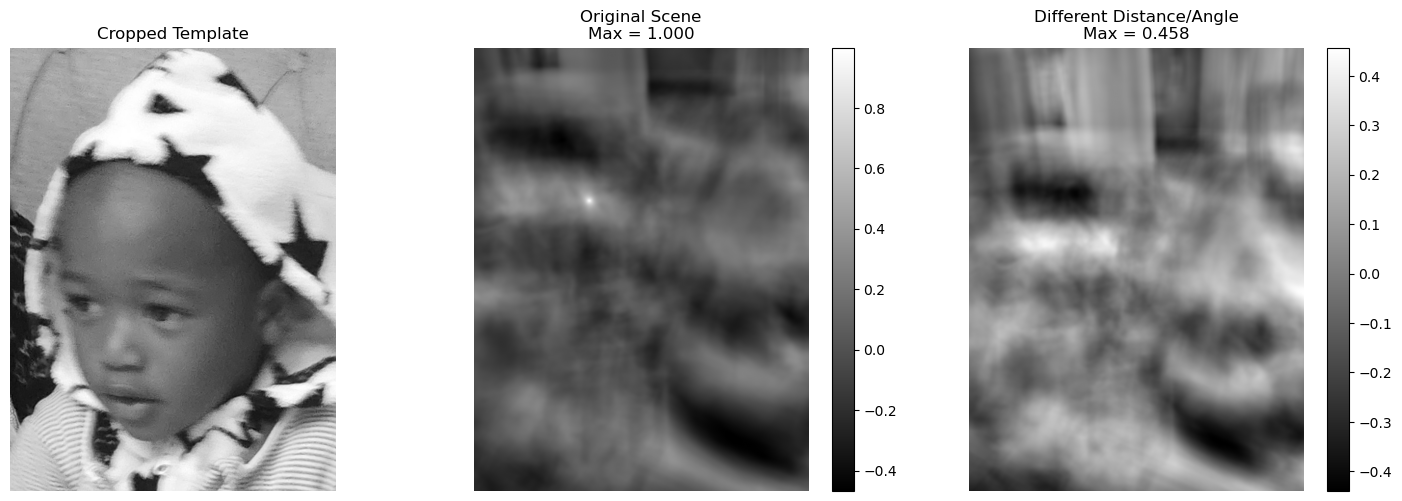

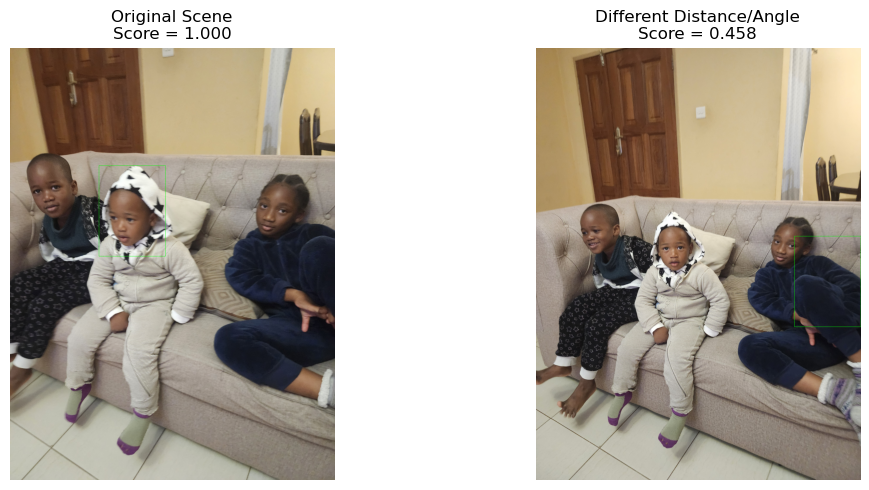


Template Matching Results
------------------------------
Original scene score: 0.9995
Changed scene score: 0.4575
Original match location: (821, 1095)
Changed match location: (2385, 1747)


In [46]:
#####################################
# RUN THE PIPELINE
#####################################
results = template_matching_pipeline(
    scene1_path=image_1_path,
    scene2_path=image_2_path,
    template_path=cropped_image_path
)

print("\nTemplate Matching Results")
print("-" * 30)
print(
    f"Original scene score: "
    f"{results['original_score']:.4f}"
)
print(
    f"Changed scene score: "
    f"{results['changed_score']:.4f}"
)
print(
    f"Original match location: "
    f"{results['original_location']}"
)
print(
    f"Changed match location: "
    f"{results['changed_location']}"
)

## Task 2. Viola-Jones face detection

In [46]:
#############################################
# LOAD FACE CASCADE
##############################################
def load_face_cascade(cascade_path):
    cascade = cv2.CascadeClassifier(cascade_path)

    if cascade.empty():
        raise FileNotFoundError(
            f"Could not load Haar cascade: {cascade_path}"
        )

    return cascade
    

In [47]:
cascade_path = cv2.data.haarcascades + \
    "haarcascade_frontalface_default.xml"

face_cascade = load_face_cascade(cascade_path)

print("Haar cascade loaded successfully.")


Haar cascade loaded successfully.


In [50]:
#############################################
# FACE DETECTION FUNCTION
##############################################
def detect_faces(
    image,
    face_cascade,
    scale_factor=1.1,
    min_neighbors=5
):
    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=scale_factor,
        minNeighbors=min_neighbors
    )

    return faces

In [9]:
#############################################
# ANNOTATE DETECTED FACES
##############################################
def annotate_faces(
    image,
    faces,
    label=True
):
    annotated = image.copy()

    for i, (x, y, w, h) in enumerate(faces):
        cv2.rectangle(
            annotated,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        if label:
            cv2.putText(
                annotated,
                f"Face {i + 1}",
                (x, y - 10),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 255, 0),
                2
            )

    return annotated

In [10]:
#############################################
# RUN DETECTION ON THE GROOUP PHOTO
##############################################
def detect_group_photo(
    image_path,
    face_cascade,
    scale_factor=1.1,
    min_neighbors=5
):
    image = cv2.imread(image_path)

    if image is None:
        raise FileNotFoundError(
            f"Could not load image: {image_path}"
        )

    faces = detect_faces(
        image,
        face_cascade,
        scale_factor,
        min_neighbors
    )

    annotated = annotate_faces(
        image,
        faces
    )

    return image, annotated, faces

In [11]:
#############################################
# PARAMETER STUDY
##############################################    
def run_parameter_study(
    image_path,
    face_cascade,
    scale_factors,
    min_neighbors_values
):
    image = cv2.imread(image_path)

    if image is None:
        raise FileNotFoundError(
            f"Could not load image: {image_path}"
        )

    results = []

    for scale_factor in scale_factors:

        for min_neighbors in min_neighbors_values:

            faces = detect_faces(
                image,
                face_cascade,
                scale_factor=scale_factor,
                min_neighbors=min_neighbors
            )

            detections = len(faces)

            results.append({
                "scaleFactor": scale_factor,
                "minNeighbors": min_neighbors,
                "Detections": detections
            })

    return pd.DataFrame(results)

In [12]:
#############################################
# COUNTING MISSING FACES AND FALSE POSITIVES
##############################################
GROUND_TRUTH_FACES = 6
def calculate_errors(
    detections,
    ground_truth_faces
):
    missed_faces = max(
        ground_truth_faces - detections,
        0
    )

    return missed_faces

In [16]:
#################################################
# SAVE ANNOTATED RESULTS FOR ALL 9 CONFIGURATIONS
#################################################
def save_parameter_results(
    image_path,
    face_cascade,
    scale_factors,
    min_neighbors_values,
    output_dir="haar_parameter_results"
):
    os.makedirs(
        output_dir,
        exist_ok=True
    )

    image = cv2.imread(image_path)

    for scale_factor in scale_factors:

        for min_neighbors in min_neighbors_values:

            faces = detect_faces(
                image,
                face_cascade,
                scale_factor,
                min_neighbors
            )

            annotated = annotate_faces(
                image,
                faces
            )

            filename = (
                f"scale_{scale_factor}_"
                f"neighbors_{min_neighbors}.jpg"
            )

            output_path = os.path.join(
                output_dir,
                filename
            )

            cv2.imwrite(
                output_path,
                annotated
            )

            print(
                f"{filename}: "
                f"{len(faces)} detections"
            )

#### Process the video

In [22]:
###################################################
# PROCESS THE VIDEO FRAME BY FRAME
################################################### 
def process_video(
    input_path,
    output_path,
    face_cascade,
    scale_factor=1.1,
    min_neighbors=5
):
    cap = cv2.VideoCapture(input_path)

    if not cap.isOpened():
        raise FileNotFoundError(
            f"Could not open video: {input_path}"
        )

    # Video properties
    fps = cap.get(cv2.CAP_PROP_FPS)

    width = int(
        cap.get(cv2.CAP_PROP_FRAME_WIDTH)
    )

    height = int(
        cap.get(cv2.CAP_PROP_FRAME_HEIGHT)
    )

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    # Output video
    fourcc = cv2.VideoWriter_fourcc(*"mp4v")

    writer = cv2.VideoWriter(
        output_path,
        fourcc,
        fps,
        (width, height)
    )

    # Statistics
    frame_count = 0
    total_detections = 0
    min_detections = float("inf")
    max_detections = 0
    zero_detection_frames = 0

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        # Detect faces
        faces = detect_faces(
            frame,
            face_cascade,
            scale_factor,
            min_neighbors
        )

        detection_count = len(faces)

        # Update statistics
        frame_count += 1
        total_detections += detection_count

        min_detections = min(
            min_detections,
            detection_count
        )

        max_detections = max(
            max_detections,
            detection_count
        )

        if detection_count == 0:
            zero_detection_frames += 1

        # Annotate frame
        annotated = annotate_faces(
            frame,
            faces
        )

        # Add information to frame
        cv2.putText(
            annotated,
            f"Faces: {detection_count}",
            (20, 40),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            (0, 255, 0),
            2
        )

        # Write annotated frame
        writer.write(annotated)

    cap.release()
    writer.release()

    # Calculate average
    average_detections = (
        total_detections / frame_count
        if frame_count > 0
        else 0
    )

    # Return results
    results = {
        "total_frames": frame_count,
        "total_detections": total_detections,
        "average_faces_per_frame": average_detections,
        "minimum_faces": min_detections,
        "maximum_faces": max_detections,
        "frames_with_no_detection": zero_detection_frames,
        "fps": fps,
        "video_width": width,
        "video_height": height,
        "output_path": output_path
    }

    return results

In [23]:
#############################################
# PROCESS PHOTO
##############################################

# Paths
photo_path = faces_path

# Cascade
cascade_path = cv2.data.haarcascades + \
    "haarcascade_frontalface_default.xml"

face_cascade = load_face_cascade(
    cascade_path
)


# A. Parameter study on group photo

scale_factors = [1.05, 1.1, 1.3]
min_neighbors_values = [3, 5, 8]

results = run_parameter_study(
    photo_path,
    face_cascade,
    scale_factors,
    min_neighbors_values
)

print("\nParameter Study")
print(results)



# B. Save annotated images for manual TP/FN/FP analysis

save_parameter_results(
    photo_path,
    face_cascade,
    scale_factors,
    min_neighbors_values
)




Parameter Study
   scaleFactor  minNeighbors  Detections
0         1.05             3           7
1         1.05             5           6
2         1.05             8           4
3         1.10             3           4
4         1.10             5           3
5         1.10             8           2
6         1.30             3           2
7         1.30             5           2
8         1.30             8           2
scale_1.05_neighbors_3.jpg: 7 detections
scale_1.05_neighbors_5.jpg: 6 detections
scale_1.05_neighbors_8.jpg: 4 detections
scale_1.1_neighbors_3.jpg: 4 detections
scale_1.1_neighbors_5.jpg: 3 detections
scale_1.1_neighbors_8.jpg: 2 detections
scale_1.3_neighbors_3.jpg: 2 detections
scale_1.3_neighbors_5.jpg: 2 detections
scale_1.3_neighbors_8.jpg: 2 detections


In [24]:

# C. Process video

video_results = process_video(
    video_path,
    "video/annotated_group_video.mp4",
    face_cascade,
    scale_factor=1.1,
    min_neighbors=5
)

print("VIDEO DETECTION RESULTS")
print("=" * 35)

print(
    f"Total frames processed: "
    f"{video_results['total_frames']}"
)

print(
    f"Total face detections: "
    f"{video_results['total_detections']}"
)

print(
    f"Average faces per frame: "
    f"{video_results['average_faces_per_frame']:.2f}"
)

print(
    f"Minimum faces in a frame: "
    f"{video_results['minimum_faces']}"
)

print(
    f"Maximum faces in a frame: "
    f"{video_results['maximum_faces']}"
)

print(
    f"Frames with no detection: "
    f"{video_results['frames_with_no_detection']}"
)

print(
    f"Video FPS: "
    f"{video_results['fps']:.2f}"
)

print(
    f"Output video: "
    f"{video_results['output_path']}"
)

VIDEO DETECTION RESULTS
Total frames processed: 429
Total face detections: 139
Average faces per frame: 0.32
Minimum faces in a frame: 0
Maximum faces in a frame: 2
Frames with no detection: 298
Video FPS: 29.94
Output video: annotated_group_video.mp4


## Task 3. Modern one-shot detection with YOLO

In [28]:
##########################################
# LOAD PRETRAINED MODEL
#########################################
def load_yolo_model(model_path="yolov8n.pt"):
    """
    Load a pretrained YOLOv8 model.
    """
    model = YOLO(model_path)

    return model
yolo_model = load_yolo_model()

In [22]:
##########################################
# LOAD IMAGES
#########################################
def load_image(image_path):
    image = cv2.imread(image_path)

    if image is None:
        raise FileNotFoundError(
            f"Could not load image: {image_path}"
        )

    return image

In [31]:
##########################
# YOLO DETECTION FUNCTION
##########################
def detect_with_yolo(
    model,
    image,
    confidence=0.25,
    classes=None
):
    """
    Run YOLO detection on an image.

    Parameters:
        model      : YOLO model
        image      : input image
        confidence : confidence threshold
        classes    : optional list of class IDs

    Returns:
        YOLO Results object
    """

    results = model.predict(
        source=image,
        conf=confidence,
        classes=classes,
        verbose=False
    )

    return results[0]

In [24]:
##########################################
# GET DETECTION RESULTS
#########################################
def get_detection_data(result):
    """
    Extract bounding boxes, confidence scores
    and class IDs from a YOLO result.
    """

    boxes = result.boxes

    detections = []

    for i in range(len(boxes)):

        xyxy = boxes.xyxy[i].cpu().numpy()
        confidence = float(
            boxes.conf[i].cpu().numpy()
        )
        class_id = int(
            boxes.cls[i].cpu().numpy()
        )

        detections.append({
            "box": xyxy,
            "confidence": confidence,
            "class_id": class_id
        })

    return detections

In [25]:
##########################################
# ANNOTATE DETECTIONS
#########################################
def annotate_yolo_result(result):
    """
    Draw YOLO bounding boxes and labels.
    """

    annotated = result.plot()

    return annotated

In [26]:
##########################################
# DISPLAY IMAGE
#########################################
def display_image(
    image,
    title="Image",
    figsize=(10, 7)
):
    """
    Display an OpenCV image using Matplotlib.
    """

    plt.figure(figsize=figsize)

    plt.imshow(
        cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )
    )

    plt.title(title)
    plt.axis("off")
    plt.show()

In [27]:
##########################################
# GROUP PHOTO PIPELINGE
#########################################
#COCO class id
PERSON_CLASS = 0

def group_photo_pipeline(
    model,
    image_path,
    confidence=0.25
):
    """
    YOLO person-detection pipeline for
    the group photograph.
    """

    # 1. Load
    image = load_image(image_path)

    # 2. Detect people
    result = detect_with_yolo(
        model=model,
        image=image,
        confidence=confidence,
        classes=[PERSON_CLASS]
    )

    # 3. Extract detection information
    detections = get_detection_data(result)

    # 4. Annotate
    annotated = annotate_yolo_result(result)

    # 5. Display
    display_image(
        annotated,
        title=(
            f"YOLOv8n Person Detection "
            f"({len(detections)} detections)"
        )
    )

    return {
        "result": result,
        "detections": detections,
        "count": len(detections),
        "annotated": annotated
    }

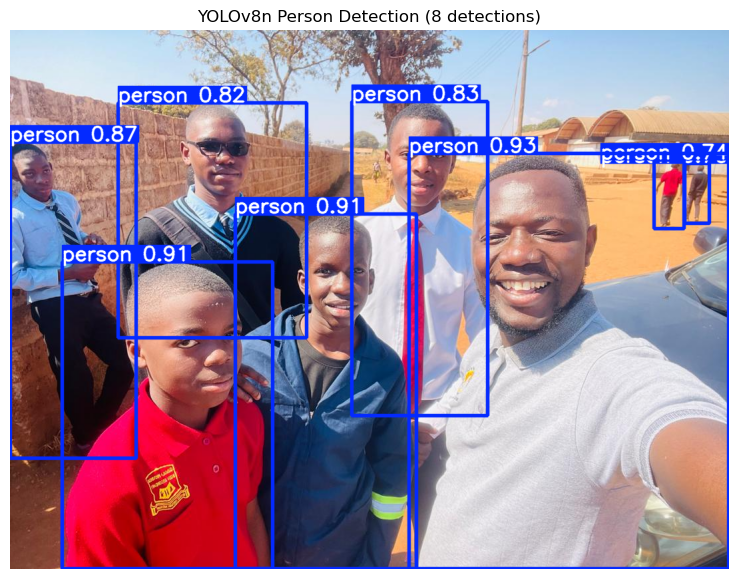

People detected: 8


In [32]:
group_photo_results = group_photo_pipeline(
    model=yolo_model,
    image_path=faces_path,
    confidence=0.25
)

print(
    "People detected:",
    group_photo_results["count"]
)

In [33]:
##########################################
# CONFIDENCE STUDY
#########################################
def run_confidence_study(
    model,
    image,
    confidence_values,
    classes=None
):
    """
    Evaluate YOLO detection at several
    confidence thresholds.
    """

    results = []

    for confidence in confidence_values:

        result = detect_with_yolo(
            model=model,
            image=image,
            confidence=confidence,
            classes=classes
        )

        detections = get_detection_data(
            result
        )

        results.append({
            "Confidence": confidence,
            "Detections": len(detections)
        })

    return pd.DataFrame(results)

In [34]:
##########################################
# CONFIDENCE STUDY PIPELINE
#########################################
def confidence_study_pipeline(
    model,
    image_path,
    confidence_values,
    classes=None
):
    """
    Complete confidence-threshold pipeline.
    """

    # Load image
    image = load_image(image_path)

    # Run experiment
    results = run_confidence_study(
        model=model,
        image=image,
        confidence_values=confidence_values,
        classes=classes
    )

    # Display results
    print(results)

    return results

In [35]:
confidence_values = [
    0.10,
    0.25,
    0.50,
    0.75
]

confidence_results = confidence_study_pipeline(
    model=yolo_model,
    image_path=faces_path,
    confidence_values=confidence_values,
    classes=[PERSON_CLASS]
)

   Confidence  Detections
0        0.10           8
1        0.25           8
2        0.50           8
3        0.75           6


In [36]:
##########################################
# PLOT CONFIDENCE RESULTS
#########################################
def plot_confidence_results(
    results,
    title="Confidence Threshold Study"
):
    """
    Plot number of detections against
    confidence threshold.
    """

    plt.figure(figsize=(8, 5))

    plt.plot(
        results["Confidence"],
        results["Detections"],
        marker="o"
    )

    plt.xlabel(
        "Confidence Threshold"
    )

    plt.ylabel(
        "Number of Detections"
    )

    plt.title(title)

    plt.grid(True)

    plt.show()

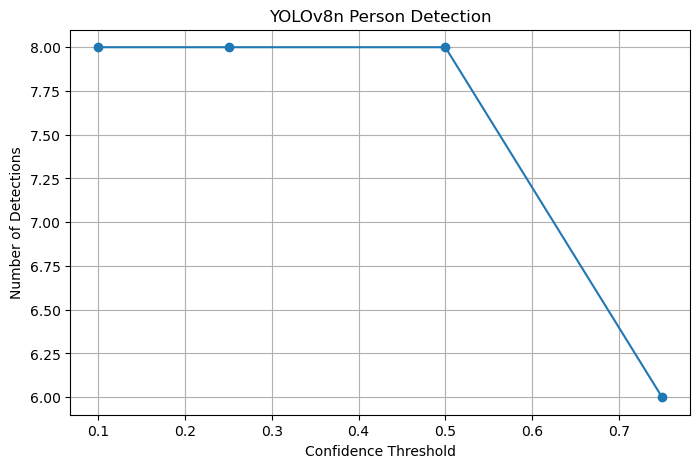

In [37]:
plot_confidence_results(
    confidence_results,
    "YOLOv8n Person Detection"
)

In [52]:
##########################################
# EVERYDAY OBJECTS
#########################################
def objects_image_pipeline(
    model,
    image_path,
    confidence=0.25
):
    """
    YOLO pipeline for everyday-object detection.
    """

    # Load
    image = load_image(
        image_path
    )

    # Detect all classes
    result = detect_with_yolo(
        model=model,
        image=image,
        confidence=confidence
    )

    # Extract detections
    detections = get_detection_data(
        result
    )

    # Annotate
    annotated = annotate_yolo_result(
        result
    )
    cv2.imwrite("yolo_image_annotated/yolo_image.jpg", annotated)
    # Display
    display_image(
        annotated,
        title=(
            f"YOLOv8n Everyday Objects "
            f"({len(detections)} detections)"
        )
    )

    return {
        "result": result,
        "detections": detections,
        "count": len(detections),
        "annotated": annotated
    }

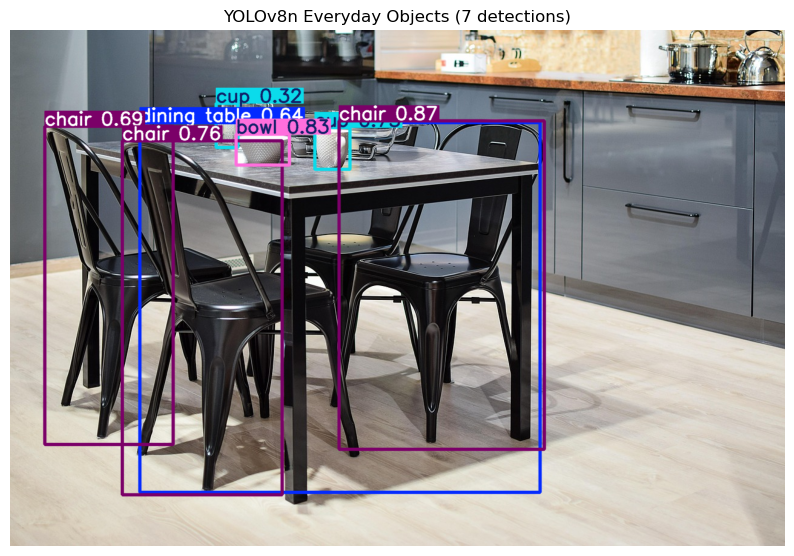

Objects detected: 7


In [53]:
objects_results = objects_image_pipeline(
    model=yolo_model,
    image_path=everyday_things_path,
    confidence=0.25
)

print(
    "Objects detected:",
    objects_results["count"]
)

In [40]:
##########################################
# VIDEO PIPELINE
#########################################
def process_yolo_video(
    model,
    input_path,
    output_path,
    confidence=0.25,
    classes=None
):
    """
    Process a video frame by frame using YOLO.
    """

    cap = cv2.VideoCapture(
        input_path
    )

    if not cap.isOpened():
        raise FileNotFoundError(
            f"Could not open video: {input_path}"
        )

    fps = cap.get(
        cv2.CAP_PROP_FPS
    )

    width = int(
        cap.get(
            cv2.CAP_PROP_FRAME_WIDTH
        )
    )

    height = int(
        cap.get(
            cv2.CAP_PROP_FRAME_HEIGHT
        )
    )

    frame_times = []
    detection_counts = []

    writer = cv2.VideoWriter(
        output_path,
        cv2.VideoWriter_fourcc(
            *"mp4v"
        ),
        fps,
        (width, height)
    )

    frame_count = 0

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        # Start timing
        start = time.perf_counter()

        # YOLO detection
        result = detect_with_yolo(
            model=model,
            image=frame,
            confidence=confidence,
            classes=classes
        )

        # End timing
        elapsed = (
            time.perf_counter() - start
        )

        frame_times.append(
            elapsed
        )

        # Count detections
        detections = get_detection_data(
            result
        )

        detection_counts.append(
            len(detections)
        )

        # Annotate
        annotated = annotate_yolo_result(
            result
        )

        # Add detection count
        cv2.putText(
            annotated,
            f"Detections: {len(detections)}",
            (20, 40),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            (0, 255, 0),
            2
        )

        # Write
        writer.write(
            annotated
        )

        frame_count += 1

    cap.release()
    writer.release()

    # Calculate statistics
    average_time = (
        sum(frame_times)
        / len(frame_times)
    )

    average_detections = (
        sum(detection_counts)
        / len(detection_counts)
    )

    return {
        "frames": frame_count,
        "total_detections": sum(
            detection_counts
        ),
        "average_detections": (
            average_detections
        ),
        "average_time_seconds": (
            average_time
        ),
        "average_time_ms": (
            average_time * 1000
        ),
        "min_detections": min(
            detection_counts
        ),
        "max_detections": max(
            detection_counts
        ),
        "output_video": output_path
    }

In [41]:
street_video_results = process_yolo_video(
    model=yolo_model,
    input_path=video_path,
    output_path="video/yolo_video.mp4",
    confidence=0.25
)

In [42]:
print("YOLO VIDEO RESULTS")
print("=" * 35)

print(
    f"Frames processed: "
    f"{street_video_results['frames']}"
)

print(
    f"Total detections: "
    f"{street_video_results['total_detections']}"
)

print(
    f"Average detections/frame: "
    f"{street_video_results['average_detections']:.2f}"
)

print(
    f"Minimum detections/frame: "
    f"{street_video_results['min_detections']}"
)

print(
    f"Maximum detections/frame: "
    f"{street_video_results['max_detections']}"
)

print(
    f"Average processing time: "
    f"{street_video_results['average_time_ms']:.2f} ms/frame"
)

print(
    f"Output video: "
    f"{street_video_results['output_video']}"
)

YOLO VIDEO RESULTS
Frames processed: 429
Total detections: 3338
Average detections/frame: 7.78
Minimum detections/frame: 3
Maximum detections/frame: 16
Average processing time: 121.24 ms/frame
Output video: video/yolo_video.mp4


In [43]:
####################################
# HAAR BENCHMARK
####################################
def benchmark_haar(
    video_path,
    face_cascade,
    scale_factor=1.1,
    min_neighbors=5
):
    """
    Measure Haar face-detection time per frame.
    """

    cap = cv2.VideoCapture(
        video_path
    )

    if not cap.isOpened():
        raise FileNotFoundError(
            f"Could not open video: {video_path}"
        )

    times = []
    frames = 0

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        start = time.perf_counter()

        detect_faces(
            frame,
            face_cascade,
            scale_factor,
            min_neighbors
        )

        elapsed = (
            time.perf_counter() - start
        )

        times.append(elapsed)
        frames += 1

    cap.release()

    average_time = (
        sum(times) / len(times)
    )

    return {
        "frames": frames,
        "average_time_ms":
            average_time * 1000
    }

In [44]:
################################################
# COMBINED BENCHMARK PIPELINE
################################################
def benchmark_detectors(
    video_path,
    face_cascade,
    yolo_model,
    haar_scale_factor=1.1,
    haar_min_neighbors=5,
    yolo_confidence=0.25
):
    """
    Compare Haar and YOLO processing time
    on the same video.
    """

    # Haar
    haar_results = benchmark_haar(
        video_path,
        face_cascade,
        haar_scale_factor,
        haar_min_neighbors
    )

    # YOLO
    yolo_results = process_yolo_video(
        model=yolo_model,
        input_path=video_path,
        output_path="benchmark_yolo.mp4",
        confidence=yolo_confidence
    )

    comparison = pd.DataFrame([
        {
            "Detector": "Viola-Jones Haar",
            "Frames": haar_results["frames"],
            "Average ms/frame":
                haar_results[
                    "average_time_ms"
                ]
        },
        {
            "Detector": "YOLOv8n",
            "Frames": yolo_results["frames"],
            "Average ms/frame":
                yolo_results[
                    "average_time_ms"
                ]
        }
    ])

    return comparison

In [51]:
#########################################
# USING face_cascade FROM TASK 2
##########################################
benchmark_results = benchmark_detectors(
    video_path="video/yolo_video.mp4",
    face_cascade=face_cascade,
    yolo_model=yolo_model
)

print(benchmark_results)

           Detector  Frames  Average ms/frame
0  Viola-Jones Haar     429        410.181193
1           YOLOv8n     429        280.991545


## Task 4. Your first vision app

## Task 5. Ethics reflection